<a href="https://colab.research.google.com/github/Viss-budi/pm-turi4-clustering-AvisBudimanTauladani/blob/main/pm_turi4_clustering_AvisBudimanTauladani_2488010002.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Persiapan: Dataset Segmentasi Pelanggan (buatan)
Modul memakai dataset buatan dengan tiga fitur: `usia` (tahun), `pendapatan` (juta Rp/tahun), dan `skor_belanja` (1–100). Data dibangkitkan dari tiga kelompok pelanggan dengan `seed` tetap agar hasil dapat direproduksi. **Label kelompok asal tidak disimpan**, sehingga data diperlakukan sebagai data tanpa label.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def kelompok(n, usia, pendapatan, skor):
    return np.c_[rng.normal(*usia, n), rng.normal(*pendapatan, n), rng.normal(*skor, n)]

data = np.vstack([
    kelompok(70, (25, 4), (45, 8),  (80, 8)),    # muda, pendapatan menengah, gemar belanja
    kelompok(65, (42, 5), (110, 12), (35, 10)),  # usia matang, pendapatan tinggi, belanja rendah
    kelompok(65, (57, 5), (65, 10), (52, 8)),    # usia senior, pendapatan menengah, belanja sedang
])

df = pd.DataFrame(data, columns=['usia', 'pendapatan', 'skor_belanja'])
df = df.clip(lower=[18, 10, 1], upper=[75, 200, 100]).round(1)
df['usia'] = df['usia'].round().astype(int)
df['skor_belanja'] = df['skor_belanja'].round().astype(int)

print(df.shape)
df.head()

(200, 3)


,usia,pendapatan,skor_belanja
0,26,34.8,83
1,21,35.9,72
2,28,37.6,63
3,29,49.0,82
4,18,46.1,74


In [2]:
df.describe().round(1)

,usia,pendapatan,skor_belanja
count,200.0,200.0,200.0
mean,40.9,72.7,55.8
std,13.7,29.6,20.4
min,18.0,31.2,12.0
25%,27.8,47.4,40.0
50%,41.0,64.8,52.0
75%,53.0,101.7,74.2
max,67.0,131.8,97.0


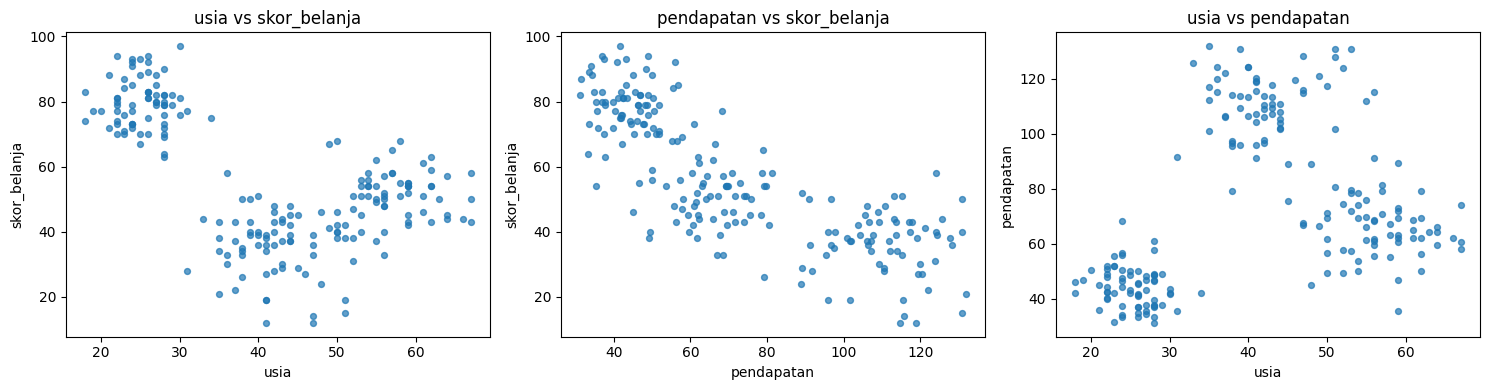

In [3]:
# Sebaran data mentah (belum ada cluster)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (x, y) in zip(ax, [('usia','skor_belanja'), ('pendapatan','skor_belanja'), ('usia','pendapatan')]):
    a.scatter(df[x], df[y], s=18, alpha=.7)
    a.set_xlabel(x); a.set_ylabel(y); a.set_title(f'{x} vs {y}')
plt.tight_layout(); plt.show()

## Langkah 1 — Menyiapkan data & scaling (wajib)
K-Means berbasis jarak Euclidean. Karena skala fitur berbeda jauh (pendapatan ratusan, usia puluhan), semua fitur distandarkan ke rata-rata 0 dan simpangan baku 1 dengan `StandardScaler`.

In [4]:
from sklearn.preprocessing import StandardScaler

# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)

print('Rata-rata  :', X_scaled.mean(axis=0).round(3))
print('Std. deviasi:', X_scaled.std(axis=0).round(3))

Rata-rata  : [0. 0. 0.]
Std. deviasi: [1. 1. 1.]


## Langkah 2 — Metode Elbow menentukan K

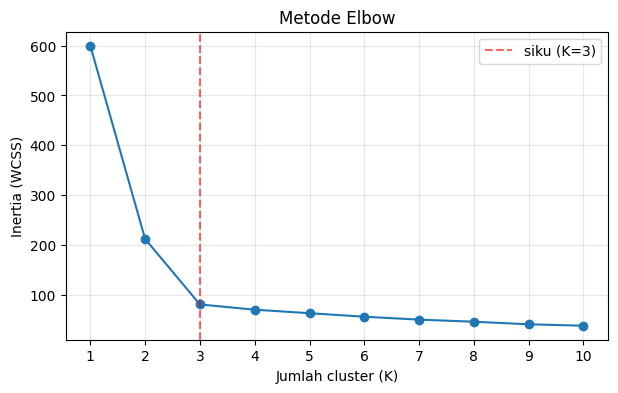

,inertia,penurunan
K,,
1,600.0,NaN
2,211.7,388.3
3,80.1,131.6
4,69.5,10.5
5,62.5,7.0
6,55.5,7.0
7,49.6,5.9
8,45.4,4.1
9,40.2,5.2


In [5]:
from sklearn.cluster import KMeans

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertias, marker='o')
plt.axvline(3, color='red', ls='--', alpha=.6, label='siku (K=3)')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia (WCSS)')
plt.title('Metode Elbow'); plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=.3)
plt.show()

# Penurunan inertia tiap kenaikan K (untuk melihat di mana penurunan mulai landai)
pd.DataFrame({'K': range(1, 11), 'inertia': np.round(inertias, 1),
              'penurunan': [np.nan] + list(np.round(-np.diff(inertias), 1))}).set_index('K')

**Hasil pengamatan Elbow.** Inertia turun tajam dari K=1 → K=2 → K=3 (≈ 600 → 212 → 80), setelah itu penurunannya landai (K=4 hanya ≈ 70 dan seterusnya semakin kecil). Titik "siku" ada di **K = 3**, sehingga K = 3 dipilih.

## Langkah 3 — Menjalankan K-Means (K=3)

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())

cluster
0    65
1    70
2    65
Name: count, dtype: int64


## Langkah 4 — Evaluasi silhouette score

In [7]:
from sklearn.metrics import silhouette_score

sil_k3 = silhouette_score(X_scaled, df['cluster'])
print(f'Silhouette score (K=3, scaled): {sil_k3:.4f}')

Silhouette score (K=3, scaled): 0.6426


Silhouette berkisar −1 s.d. 1; semakin mendekati 1 berarti cluster padat dan terpisah baik. Nilai ≈ 0,64 (> 0,5) menunjukkan struktur cluster yang **kuat/jelas**.

## Langkah 5 — Interpretasi: profil rata-rata tiap cluster

In [8]:
profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
profil['jumlah'] = df['cluster'].value_counts().sort_index()
print(profil)

         usia  pendapatan  skor_belanja  jumlah
cluster                                        
0        56.6        65.4          50.7      65
1        25.3        44.0          79.5      70
2        42.1       110.8          35.3      65


In [9]:
# Penamaan cluster otomatis berdasarkan profil (agar tidak bergantung pada nomor cluster yang acak)
nama = {}
nama[profil['skor_belanja'].idxmax()] = 'Muda Gemar Belanja'
nama[profil['pendapatan'].idxmax()]   = 'Mapan Hemat'
nama[profil['usia'].idxmax()]         = 'Senior Moderat'
assert len(nama) == 3, 'Penamaan bertabrakan, periksa profil cluster'

df['segmen'] = df['cluster'].map(nama)
profil['segmen'] = profil.index.map(nama)
profil

,usia,pendapatan,skor_belanja,jumlah,segmen
cluster,,,,,
0,56.6,65.4,50.7,65,Senior Moderat
1,25.3,44.0,79.5,70,Muda Gemar Belanja
2,42.1,110.8,35.3,65,Mapan Hemat


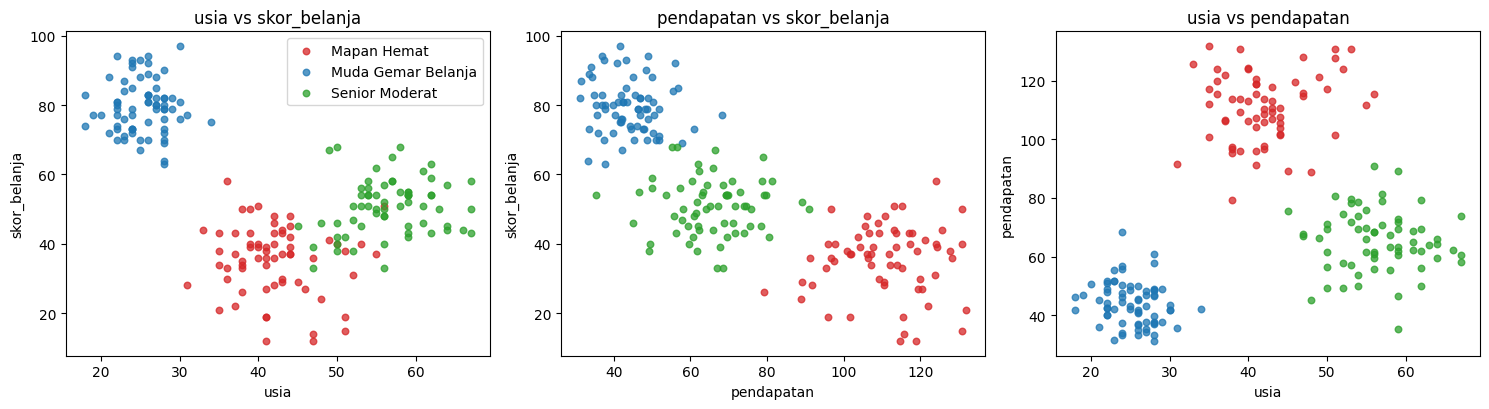

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
warna = {'Muda Gemar Belanja':'#1f77b4', 'Mapan Hemat':'#d62728', 'Senior Moderat':'#2ca02c'}
for a, (x, y) in zip(ax, [('usia','skor_belanja'), ('pendapatan','skor_belanja'), ('usia','pendapatan')]):
    for s, g in df.groupby('segmen'):
        a.scatter(g[x], g[y], s=22, alpha=.75, label=s, color=warna[s])
    a.set_xlabel(x); a.set_ylabel(y); a.set_title(f'{x} vs {y}')
ax[0].legend(); plt.tight_layout(); plt.show()

### Penamaan & Interpretasi Cluster
| Segmen | Ciri utama | Saran strategi |
|---|---|---|
| **Muda Gemar Belanja** | Usia termuda (±25 th), pendapatan menengah (±45 jt), skor belanja tinggi (±80) | Promo, flash sale, program loyalitas, kampanye media sosial |
| **Mapan Hemat** | Usia matang (±42 th), pendapatan tertinggi (±110 jt), skor belanja rendah (±35) | Produk premium/eksklusif, personalisasi, layanan bernilai tambah — daya beli besar namun belum tergali |
| **Senior Moderat** | Usia tertua (±57 th), pendapatan menengah (±65 jt), skor belanja sedang (±52) | Kemudahan layanan, kualitas & kepercayaan, program keanggotaan |

## Latihan Mandiri

### Latihan 1 — K-Means dengan K=5, bandingkan silhouette dengan K=3

Silhouette K=3: 0.6426
Silhouette K=5: 0.4430


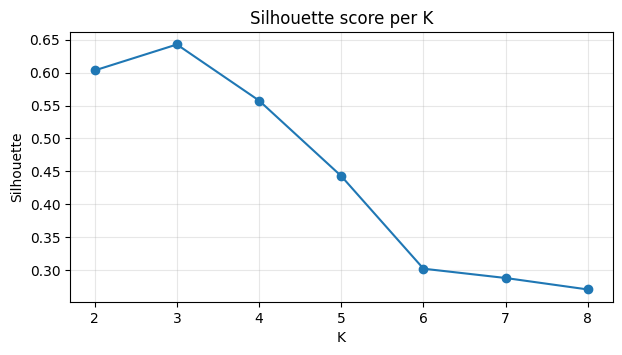

,silhouette
2,0.6032
3,0.6426
4,0.5575
5,0.4430
6,0.3025
7,0.2883
8,0.2710


In [11]:
labels_k5 = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, labels_k5)

print(f'Silhouette K=3: {sil_k3:.4f}')
print(f'Silhouette K=5: {sil_k5:.4f}')

# Pembanding tambahan: silhouette untuk K = 2..8
sil_semua = {k: silhouette_score(X_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled))
             for k in range(2, 9)}
plt.figure(figsize=(7, 3.5))
plt.plot(list(sil_semua), list(sil_semua.values()), marker='o')
plt.xlabel('K'); plt.ylabel('Silhouette'); plt.title('Silhouette score per K'); plt.grid(alpha=.3); plt.show()
pd.Series(sil_semua, name='silhouette').round(4)

**Kesimpulan Latihan 1.** Silhouette K=5 (≈ 0,44) **lebih rendah** daripada K=3 (≈ 0,64). Dengan K=5, kelompok alami yang sebenarnya hanya tiga dipecah menjadi sub-kelompok yang saling berdekatan, sehingga jarak antar-cluster mengecil dan banyak titik berada dekat batas cluster. Ini selaras dengan hasil Elbow: K=3 adalah pilihan terbaik.

### Latihan 2 — K-Means tanpa scaling (K=3), bandingkan silhouette

In [12]:
km_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_raw = km_raw.fit_predict(df[['usia','pendapatan','skor_belanja']])   # data MENTAH, tanpa scaling
sil_raw = silhouette_score(df[['usia','pendapatan','skor_belanja']], labels_raw)

print(f'Silhouette dengan scaling   : {sil_k3:.4f}')
print(f'Silhouette tanpa scaling    : {sil_raw:.4f}  (dihitung pada ruang data mentah)')

# Seberapa mirip hasil pengelompokannya? (1 = identik)
from sklearn.metrics import adjusted_rand_score
print(f'Adjusted Rand Index (scaled vs raw): {adjusted_rand_score(df["cluster"], labels_raw):.4f}')

# Kontribusi tiap fitur terhadap jarak pada data mentah: rentang nilai fitur
print('\nStd. deviasi tiap fitur (data mentah):')
print(df[['usia','pendapatan','skor_belanja']].std().round(1))

Silhouette dengan scaling   : 0.6426
Silhouette tanpa scaling    : 0.6323  (dihitung pada ruang data mentah)
Adjusted Rand Index (scaled vs raw): 1.0000

Std. deviasi tiap fitur (data mentah):
usia            13.7
pendapatan      29.6
skor_belanja    20.4
dtype: float64


In [13]:
# Bandingkan seberapa seragam pengaruh fitur pada pemisahan cluster:
# rasio (selisih antar pusat cluster / std. fitur) pada data mentah vs scaled
pusat_raw = pd.DataFrame(km_raw.cluster_centers_, columns=['usia','pendapatan','skor_belanja'])
print('Pusat cluster tanpa scaling:'); print(pusat_raw.round(1))
print('\nUkuran cluster tanpa scaling:', np.bincount(labels_raw))

Pusat cluster tanpa scaling:
   usia  pendapatan  skor_belanja
0  56.6        65.4          50.7
1  42.1       110.8          35.3
2  25.3        44.0          79.5

Ukuran cluster tanpa scaling: [65 65 70]


**Kesimpulan Latihan 2.** Pada data buatan ini silhouette tanpa scaling (≈ 0,63) hampir sama dengan yang ber-scaling (≈ 0,64), dan *Adjusted Rand Index* = 1,0 menunjukkan **pembagian cluster identik**. Hal ini terjadi karena ketiga segmen sudah sangat terpisah, terutama pada `pendapatan` (fitur dengan skala terbesar, std ≈ 30 dibanding usia ≈ 14 dan skor ≈ 20), sehingga dominasinya tidak mengubah hasil.

Namun silhouette kedua kondisi **tidak sepenuhnya sebanding**, karena dihitung pada ruang jarak yang berbeda. Kesimpulannya: **scaling tetap wajib** — bukan karena skor selalu naik, melainkan agar setiap fitur berkontribusi adil. Perbedaan skala pada data ini hanya sekitar 2×; pada data nyata dengan selisih skala jauh lebih besar (mis. pendapatan dalam rupiah vs usia), fitur berskala besar akan mendominasi jarak dan cluster bisa menyesatkan.

### Latihan 3 — Scatter plot cluster: usia (x) vs skor_belanja (y)

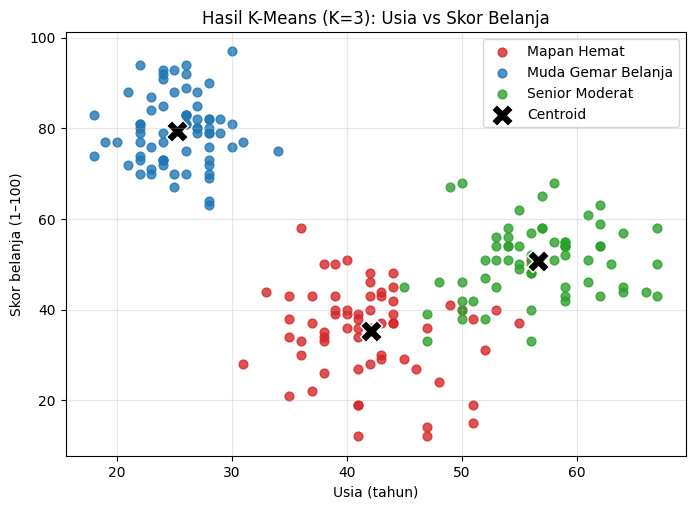

In [14]:
plt.figure(figsize=(8, 5.5))
for s, g in df.groupby('segmen'):
    plt.scatter(g['usia'], g['skor_belanja'], s=40, alpha=.8, label=s, color=warna[s])

# Centroid dikembalikan ke skala asli
pusat = StandardScaler().fit(df[['usia','pendapatan','skor_belanja']]).inverse_transform(kmeans.cluster_centers_)
pusat = pd.DataFrame(pusat, columns=['usia','pendapatan','skor_belanja'])
plt.scatter(pusat['usia'], pusat['skor_belanja'], marker='X', s=250, c='black', edgecolor='white', label='Centroid')

plt.xlabel('Usia (tahun)'); plt.ylabel('Skor belanja (1–100)')
plt.title('Hasil K-Means (K=3): Usia vs Skor Belanja'); plt.legend(); plt.grid(alpha=.3)
plt.show()

Pada bidang usia–skor belanja, segmen **Muda Gemar Belanja** terpisah jelas di kiri-atas (usia muda, skor tinggi), sedangkan **Mapan Hemat** (usia ±42, skor rendah) dan **Senior Moderat** (usia ±57, skor sedang) berada di sisi kanan-bawah dan sedikit tumpang-tindih pada skor belanja. Pembeda keduanya yang paling kuat ada pada `pendapatan` (lihat plot pendapatan vs skor di atas).

## Refleksi

**1. Bagaimana K-Means menemukan kelompok tanpa label?**
K-Means tidak memakai label; ia hanya memanfaatkan **kemiripan (jarak)** antar titik. Algoritma menempatkan K centroid awal, lalu mengulang dua langkah: (a) *assignment* — setiap titik masuk ke centroid terdekat; (b) *update* — centroid dihitung ulang sebagai rata-rata anggota clusternya. Iterasi berhenti saat centroid tidak lagi berubah (konvergen), dengan tujuan meminimalkan inertia (jumlah kuadrat jarak titik ke centroid). Titik yang berdekatan di ruang fitur akhirnya berada di cluster yang sama, sehingga struktur kelompok muncul dari data itu sendiri. Maknanya (nama segmen) baru kita berikan setelahnya lewat profil rata-rata.

**2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**
Karena data memang tersusun dari **tiga kelompok yang terpisah baik**. Dari K=1 ke K=3, setiap cluster baru memisahkan kelompok sungguhan sehingga inertia anjlok tajam (≈ 600 → 212 → 80). Setelah K=3, penambahan cluster hanya memecah kelompok yang sudah padat, sehingga penurunan inertia kecil dan grafik melandai — membentuk siku. Silhouette tertinggi di K=3 juga mendukung hal ini.

**3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**
K-Means memakai jarak Euclidean, sehingga fitur berskala besar (mis. `pendapatan`) mendominasi perhitungan jarak, sedangkan fitur berskala kecil (`usia`, `skor_belanja`) kurang berpengaruh. Tanpa scaling, cluster pada dasarnya hanya mencerminkan satu fitur dan bisa bias/menyesatkan. `StandardScaler` menyamakan skala sehingga tiap fitur berkontribusi seimbang. Pada percobaan ini hasilnya identik karena kelompok sudah sangat terpisah dan selisih skala fitur hanya sekitar 2×, tetapi itu tidak berlaku umum.

## Kesimpulan
1. Data distandarkan dengan `StandardScaler` sebelum K-Means karena algoritma berbasis jarak.
2. Metode Elbow menunjukkan siku pada **K = 3**, didukung silhouette tertinggi (≈ 0,64) dibanding K=5 (≈ 0,44).
3. Tiga segmen pelanggan teridentifikasi: **Muda Gemar Belanja**, **Mapan Hemat**, dan **Senior Moderat**, masing-masing dengan strategi pemasaran yang berbeda.
4. Scaling tetap diperlukan agar setiap fitur berkontribusi adil, meskipun pada data ini dampaknya pada silhouette kecil.